Noise: 0.00 | PCA components for 95% variance: 5 | TwoNN estimate: 2.14
Noise: 0.01 | PCA components for 95% variance: 5 | TwoNN estimate: 2.44
Noise: 0.05 | PCA components for 95% variance: 5 | TwoNN estimate: 4.12
Noise: 0.20 | PCA components for 95% variance: 5 | TwoNN estimate: 7.13


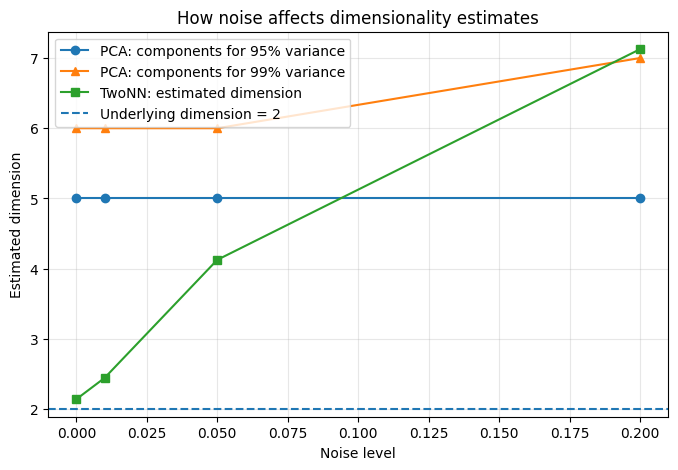

In [ ]:
# Mini-project: How many dimensions do data need?
# Compare PCA and TwoNN on synthetic data with known dimension.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.spatial import cKDTree

# 1. Generate data from two hidden variables
def make_data(noise=0.0, n=1000):
    rng = np.random.default_rng(100)

    z1 = rng.standard_normal(n)
    z2 = rng.standard_normal(n)

    X = np.column_stack([
        z1,
        z2,
        z1 + z2,
        z1 - z2,
        z1**2,
        z2**2,
        z1 * z2,
        np.sin(z1),
        np.cos(z2),
        z1 + 0.5 * z2
    ])

    X += noise * rng.standard_normal(X.shape)
    return StandardScaler().fit_transform(X)

# 2. Estimate intrinsic dimension using TwoNN
def twonn_dimension(X):
    distances, _ = cKDTree(X).query(X, k=3)

    # Ratio between distances to the second and first neighbours
    mu = distances[:, 2] / distances[:, 1]

    return len(X) / np.sum(np.log(mu))

# 3. Compare PCA and TwoNN at different noise levels
noise_levels = [0.0, 0.01, 0.05, 0.2]
pca_results = []
twonn_results = []
pca99_results = []

for noise in noise_levels:
    X = make_data(noise=noise)

    pca = PCA().fit(X)
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

    # Number of components needed to explain 95% of variance
    n_components = np.argmax(cumulative_variance >= 0.95) + 1
    n99 = np.argmax(cumulative_variance >= 0.99) + 1
    pca99_results.append(n99)

    pca_results.append(n_components)
    twonn_results.append(twonn_dimension(X))

    print(
        f"Noise: {noise:.2f} | "
        f"PCA components for 95% variance: {n_components} | "
        f"TwoNN estimate: {twonn_results[-1]:.2f}"
    )

# 4. Visualize the results
plt.figure(figsize=(8, 5))

plt.plot(noise_levels, pca_results, "o-", label="PCA: components for 95% variance")
plt.plot(noise_levels, pca99_results, "^-", label="PCA: components for 99% variance")
plt.plot(noise_levels, twonn_results, "s-", label="TwoNN: estimated dimension")

plt.axhline(2, linestyle="--", label="Underlying dimension = 2")

plt.xlabel("Noise level")
plt.ylabel("Estimated dimension")
plt.title("How noise affects dimensionality estimates")
plt.legend()
plt.grid(alpha=0.3)
plt.show()